# Breast Cancer Classification with SVM

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Compare approaches to classifying diagnostic observations.

**Approach:** scikit-learn breast-cancer dataset; support vector machines with classification baselines.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : SVM  </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE

In [28]:
# Import necessary libraries
from sklearn.datasets import load_breast_cancer
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
import seaborn as sns

### Step 1: Load the Breast Cancer Dataset
We start by loading the Breast Cancer dataset from the UCI Machine Learning Repository using sklearn.datasets. The dataset is then converted into a pandas DataFrame for easier manipulation..

In [29]:
# Load the dataset
data = load_breast_cancer()

# Convert to DataFrame for easier manipulation
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Display the first few rows of the dataset
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### Step 2: Display Information About the Data
We display basic information about the dataset, including the number of samples, features, and the distribution of the target variable. We'll also visualize the target distribution.

Number of samples: 569
Number of features: 30
Target distribution:
 target
1    357
0    212
Name: count, dtype: int64


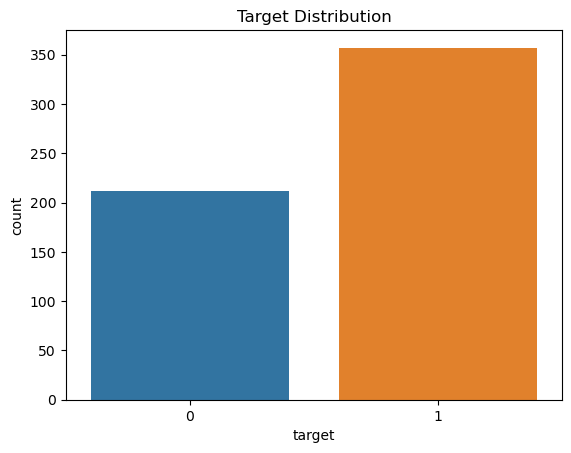

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display dataset information
print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1] - 1)  # Excluding the target column
print("Target distribution:\n", df['target'].value_counts())

# Visualize the target distribution
sns.countplot(x='target', data=df)
plt.title('Target Distribution')
plt.show()

In [31]:
# Display dataset information
print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1] - 1)  # Excluding the target column
print("Target distribution:\n", df['target'].value_counts())

Number of samples: 569
Number of features: 30
Target distribution:
 target
1    357
0    212
Name: count, dtype: int64


### Step 3: Split the Data into Training and Test Sets
The dataset is split into training and test sets using train_test_split from sklearn.model_selection. This allows us to train our model on one subset and evaluate it on another.

In [32]:


# Split the data into training and test sets
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])

Training set size: 398
Test set size: 171


### Step 4: Train the Classifier with Default Values
We initialize a LogisticRegression classifier with default parameters and train it on the training data.

In [33]:
# Initialize the classifier
clf = LogisticRegression(max_iter=10000)
# Train the classifier
clf.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

### Step 5: Predict the Test Data
Using the trained classifier, we predict the labels for the test set.

In [34]:
# Predict the test data
y_pred = clf.predict(X_test)

### Step 6: Calculate the Confusion Matrix
We calculate the confusion matrix to evaluate the performance of our classifier and visualize it.

In [35]:
# Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

Confusion Matrix:
 [[ 61   2]
 [  2 106]]


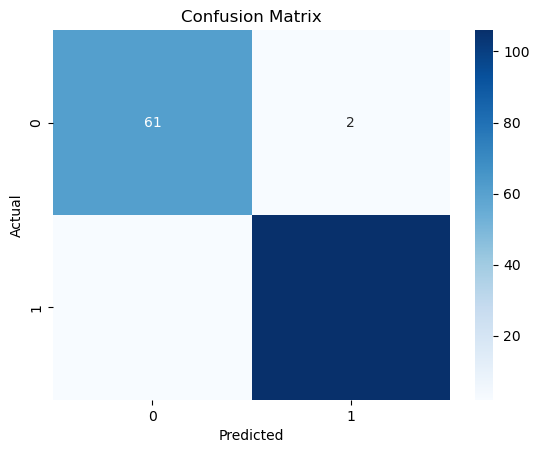

In [36]:
# Visualize the confusion matrix
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Step 7: Optimize Parameters Using GridSearch
To improve the classifier's performance, we use GridSearchCV to find the best hyperparameters.

In [22]:
# Define the parameter grid
param_grid = {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2']}

# Initialize GridSearchCV
grid_search = GridSearchCV(LogisticRegression(max_iter=10000), param_grid, cv=5)

# Perform the grid search
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best parameters:", grid_search.best_params_)

C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:378: FitFailedWarning: 
25 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
25 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1162, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\linear_model

Best parameters: {'C': 100, 'penalty': 'l2'}


### Step 8: Predict the Test Data Again with Optimized Parameters
We predict the test data again using the classifier with optimized parameters.

In [23]:
# Predict the test data with optimized parameters
y_pred_optimized = grid_search.predict(X_test)

### Step 9: Calculate the New Confusion Matrix
We calculate the confusion matrix again to see if the performance has improved after optimization and visualize it.

In [38]:
# Calculate the new confusion matrix
conf_matrix_optimized = confusion_matrix(y_test, y_pred_optimized)
print("Optimized Confusion Matrix:\n", conf_matrix_optimized)

Optimized Confusion Matrix:
 [[ 61   2]
 [  3 105]]


### Step 10: Conclusion
We conclude by comparing the initial and optimized confusion matrices to assess the impact of parameter optimization.

Initial Confusion Matrix:
 [[ 61   2]
 [  2 106]]
Optimized Confusion Matrix:
 [[ 61   2]
 [  3 105]]


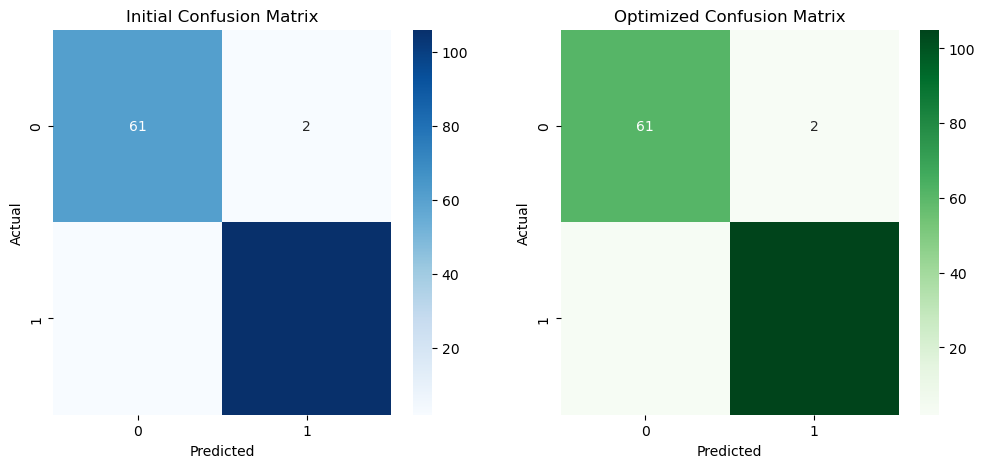

In [40]:
# Compare the performance
print("Initial Confusion Matrix:\n", conf_matrix)
print("Optimized Confusion Matrix:\n", conf_matrix_optimized)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Initial Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(conf_matrix_optimized, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Optimized Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.show()